# Charity land and lease analysis

Analyse the latest completed run in `projects/charity_lease/datasets/output/<UTC timestamp>/`.
Each row represents one **active charity**, deduplicated by registered charity number.
Both CCOD and Registered Leases evidence are retained. A qualifying charity freeholder
takes tenure precedence; otherwise a Registered Leases match selects leasehold.

This notebook covers match coverage, self-reported land/buildings, matched tenure,
lease durations and estimated years remaining, review status, and geography.
It uses `local_authority_code`, `UTLA`, and `UTLA_name` already included in the output;
no additional ONS lookup is required. UTLA names describe upper-tier authorities,
not necessarily the district represented by `local_authority_code`.

Run the pipeline using the single workflow documented in `../README.md`.

Incomplete lease sources are rejected by default. Only add `--allow-incomplete-leases`
when deliberately accepting the complete prefix of a truncated source. The run information reports its
status and the reference date used for lease estimates. Matches indicate address
similarity, not verified ownership or tenancy; unmatched rows do not establish
that a charity has no property or lease.

Launch the notebooks from the repository root with the optional analysis dependencies:
The notebooks import the installed `charity_lease` package; cohort definitions,
source validation, run discovery and geography summaries are maintained there.


```powershell
uv run --package charity-lease --extra analysis jupyter lab projects/charity_lease/notebooks
```

Use this environment's Python kernel so the editable package is importable.
Set `DATA_PATH` to pin a completed run; otherwise timestamp ordering selects one.
The comparison notebook uses `BEFORE_PATH` and `AFTER_PATH` to pin two runs.
Both notebooks read completed datasets and retain results in notebook cells.


In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

from charity_lease.data import PROJECT_DIR
from charity_lease.analysis import (
    MATCH_ORDER, SIZE_ORDER, TERM_LABELS, load_analysis_data, geographic_summary,
)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")


In [2]:
# Leave DATA_PATH as None to analyse the latest completed run.
# To pin a run, use a project-relative output path.
DATA_PATH = None
DATA_PATH, charities = load_analysis_data(DATA_PATH)
print(f"Run (UTC): {DATA_PATH.parent.name}")
print(f"Input: {DATA_PATH.relative_to(PROJECT_DIR)}")
print(f"Output charities: {len(charities):,}")
if "date_of_removal" not in charities:
    display(Markdown("**Activity not independently checked:** the register has no removal-date column."))


Run (UTC): 20260929_210521_052655Z
Input: datasets\output\20260929_210521_052655Z\charity_register_with_property.parquet
Output charities: 171,870


## Match categories and source quality

The denominator is the deduplicated output, not the historical register.
Unknown land/buildings responses remain separate. Both-source, lease-only,
CCOD-only and unmatched categories partition the population without suppressing
evidence. Review combines the flags from both selected sources.


In [3]:
reference_dates = pd.to_datetime(charities["lease_term_as_of_date"], errors="raise").dt.date.unique()
print("Lease estimate reference date(s):", ", ".join(map(str, reference_dates)))
if charities["lease_source_incomplete"].any():
    display(Markdown("**Incomplete lease source:** this run used only complete records from a truncated CSV. "
                     "Lease coverage may be understated; unmatched does not mean no lease."))
print(f"Matches flagged for review: {int(charities['review'].sum()):,}")
print(f"Unknown self-reported land/buildings: {int(charities['charity_has_land'].isna().sum()):,}")

Lease estimate reference date(s): 2026-09-29
Matches flagged for review: 70,581
Unknown self-reported land/buildings: 7,673


In [4]:
charity_has_land_order = ["True", "False", "Unknown"]
land_registry_match_order = MATCH_ORDER
has_land_vs_land_registry = pd.crosstab(
    charities["charity_has_land_label"],
    charities["land_registry_match"],
)
has_land_vs_land_registry = has_land_vs_land_registry.reindex(
    index=charity_has_land_order,
    columns=land_registry_match_order,
    fill_value=0,
)
has_land_vs_land_registry["Total"] = has_land_vs_land_registry.sum(axis=1)
has_land_vs_land_registry["Any Land Registry match"] = (
    has_land_vs_land_registry["Both sources"]
    + has_land_vs_land_registry["Registered Leases only"]
    + has_land_vs_land_registry["CCOD only"]
)
has_land_vs_land_registry["Any Land Registry match (%)"] = (
    100 * has_land_vs_land_registry["Any Land Registry match"]
    / has_land_vs_land_registry["Total"].replace(0, np.nan)
)
has_land_vs_land_registry

land_registry_match,Both sources,Registered Leases only,CCOD only,No Land Registry match,Total,Any Land Registry match,Any Land Registry match (%)
charity_has_land_label,,,,,,,
True,16531,3643,12300,24009,56483,32474,57.49
False,28609,7926,17945,53234,107714,54480,50.58
Unknown,1978,603,1340,3752,7673,3921,51.10


In [5]:
n_total = len(charities)
n_registered_leases = int(charities["matched_registered_leases"].sum())
n_both = int(charities["matched_both"].sum())
print(f"Matches in both sources: {n_both:,}")
print(f"Raw lease matches classified as freehold: {int((charities["matched_registered_leases"] & ~charities["eligible_registered_leases"]).sum()):,}")
n_any_match = int(charities["any_land_registry_match"].sum())
share_matched = 100 * n_any_match / n_total

print(f"Charities with a Registered Leases match: {n_registered_leases:,}")
print(f"Total charities: {n_total:,}")
print(
    f"Matched in Registered Leases or CCOD: "
    f"{n_any_match:,} ({share_matched:.2f}%)"
)


Matches in both sources: 47,118
Raw lease matches classified as freehold: 1,414
Charities with a Registered Leases match: 59,290
Total charities: 171,870
Matched in Registered Leases or CCOD: 90,875 (52.87%)


## Match review status

Category shares use all output charities. A row is flagged when either selected
source requires review, including the lease evidence retained for freeholders.


In [6]:
review_summary = charities.groupby("land_registry_match", observed=True).agg(
    charities=("registered_charity_number", "size"),
    needs_review=("review", "sum"),
).reindex(land_registry_match_order, fill_value=0)
review_summary["without_review_flag"] = review_summary["charities"] - review_summary["needs_review"]
review_summary["share_of_all_charities_pct"] = 100 * review_summary["charities"] / n_total
assert review_summary["charities"].sum() == n_total
assert n_any_match == n_registered_leases + int(charities["matched_ccod"].sum()) - n_both
review_summary

,charities,needs_review,without_review_flag,share_of_all_charities_pct
land_registry_match,,,,
Both sources,47118,42062,5056,27.41
Registered Leases only,12172,6662,5510,7.08
CCOD only,31585,21857,9728,18.38
No Land Registry match,80995,0,80995,47.13


## Waterfall: Land Registry matches

The opening bar is all charities. The four downward steps partition that total by Land Registry match outcome (both sources, Registered Leases only, CCOD only, or no match); percentages use all charities as the denominator.

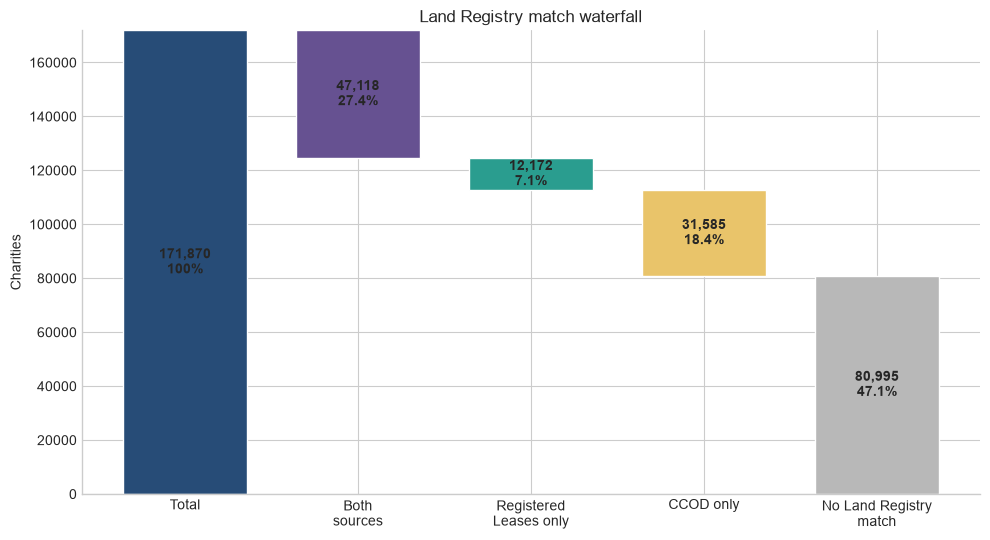

In [7]:
match_breakdown = (
    charities["land_registry_match"]
    .value_counts()
    .reindex(land_registry_match_order, fill_value=0)
)
steps = np.array([n_total, *(-match_breakdown.to_numpy())], dtype=float)
labels = [
    "Total",
    "Both\nsources",
    "Registered\nLeases only",
    "CCOD only",
    "No Land Registry\nmatch",
]
starts = np.r_[0, n_total + np.r_[0, np.cumsum(steps[1:])[:-1]]]
colors = ["#274c77", "#665191", "#2a9d8f", "#e9c46a", "#b8b8b8"]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(labels, steps, bottom=starts, color=colors, edgecolor="white", width=0.72)
for i, (step, start) in enumerate(zip(steps, starts)):
    if i == 0:
        text = f"{int(step):,}\n100%"
        y = start + step / 2
    else:
        text = f"{int(abs(step)):,}\n{abs(step) / n_total:.1%}"
        y = start + step / 2
    ax.text(i, y, text, ha="center", va="center", fontsize=10, fontweight="bold")
ax.set_ylabel("Charities")
ax.set_title("Land Registry match waterfall")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


## Tenure from selected Land Registry records

Tenure uses the pipeline `lease_status`, including the charity-freeholder exception.
CCOD-only freehold identifies property tenure and does not necessarily identify
the charity as proprietor. No data includes missing or unsupported tenure.
Land/buildings responses are stacked as False, True and Unknown; missing
responses remain Unknown. Bar shares use all output charities, and segment
percentages use the corresponding bar total.


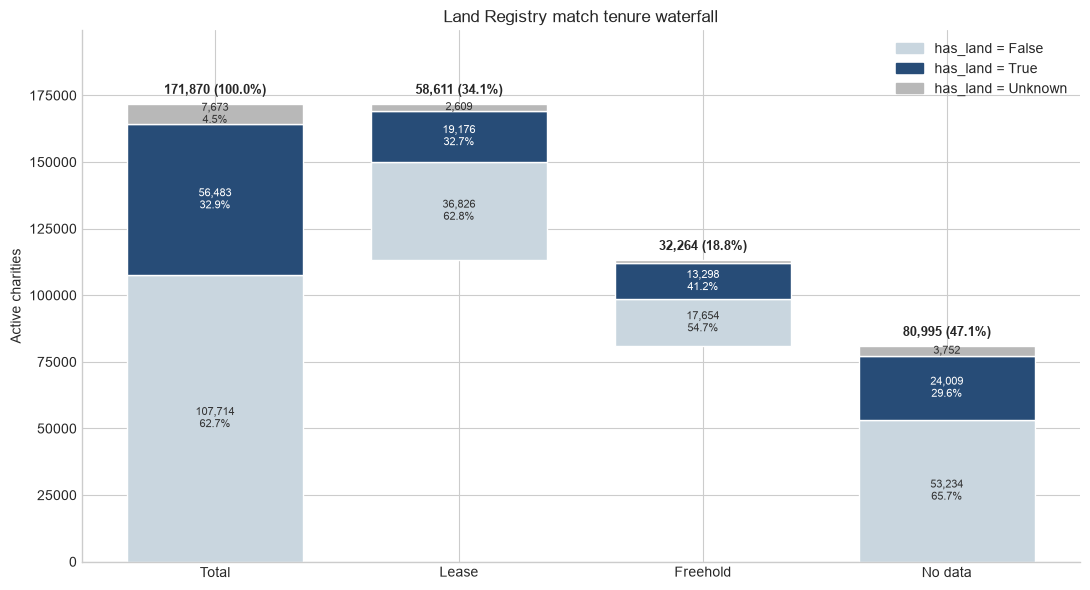

In [8]:
tenure_order = ["Lease", "Freehold", "No data"]
land_stack_order = ["False", "True", "Unknown"]
has_land = charities["charity_has_land_label"]
tenure_by_land = pd.crosstab(charities["registry_tenure"], has_land).reindex(
    index=tenure_order, columns=land_stack_order, fill_value=0)
tenure_breakdown = tenure_by_land.sum(axis=1)
stack_counts = pd.concat([
    pd.DataFrame([has_land.value_counts().reindex(land_stack_order, fill_value=0)], index=["Total"]),
    tenure_by_land,
])
colors = {"False": "#c9d6df", "True": "#274c77", "Unknown": "#b8b8b8"}
fig, ax = plt.subplots(figsize=(11, 6))
remaining = n_total
for i, (label, counts) in enumerate(stack_counts.iterrows()):
    total = int(counts.sum())
    lower = 0 if i == 0 else remaining - total
    bottom = lower
    for category in land_stack_order:
        count = int(counts[category])
        ax.bar(i, count, bottom=bottom, width=0.72, color=colors[category], edgecolor="white")
        if count and count / n_total >= 0.015:
            label_text = f"{count:,}\n{count / total:.1%}" if count / n_total >= 0.04 else f"{count:,}"
            ax.text(i, bottom + count / 2, label_text, ha="center", va="center",
                    fontsize=8, color="white" if category == "True" else "#333333")
        bottom += count
    ax.text(i, lower + total + n_total * 0.015, f"{total:,} ({total / n_total:.1%})",
            ha="center", va="bottom", fontsize=9, fontweight="bold")
    if i > 0:
        remaining -= total
assert remaining == 0
ax.set_xticks(range(len(stack_counts)), stack_counts.index)
ax.set_ylabel("Active charities")
ax.set_title("Land Registry match tenure waterfall")
ax.set_ylim(0, n_total * 1.16)
ax.legend(handles=[Patch(color=colors[c], label=f"has_land = {c}") for c in land_stack_order],
          loc="upper right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Total lease term by charity size

Only Registered Leases matches with selected `lease_status = leasehold` enter
this section. Raw lease matches classified as charity freeholders are excluded
because their lease estimates are deliberately suppressed. Total term is the duration
parsed from `lease_term`, not remaining years. Bands are left-inclusive and
right-exclusive, so fractional durations are classified correctly (for example,
124.5 years is in **100 to <125**, and 125 years is in **125+**).
Missing or nonpositive terms are **Unknown**. Each pie uses matches in that size
group as its denominator. A missing size is **Unknown size**.

In [9]:
leases = charities.loc[charities["eligible_registered_leases"]].copy()
term_labels = TERM_LABELS
term_order = term_labels + ["Unknown"]
lease_term_table = pd.crosstab(leases["charity_size"], leases["term_band"]).reindex(
    index=SIZE_ORDER,
    columns=term_order,
    fill_value=0,
)
lease_term_percent = lease_term_table.div(lease_term_table.sum(axis=1).replace(0, np.nan), axis=0).mul(100)
lease_term_percent.round(1)

term_band,Under 5 years,5 to <10 years,10 to <25 years,25 to <50 years,50 to <100 years,100 to <125 years,125+ years,Unknown
charity_size,,,,,,,,
Small,0.20,1.00,20.10,9.70,10.20,0.40,42.30,16.10
Medium,0.20,1.20,24.60,10.00,10.70,0.40,33.20,19.60
Large,0.40,1.70,27.90,7.80,10.10,0.50,26.50,25.20
Unknown size,0.30,0.80,20.00,8.30,9.20,0.60,43.20,17.70


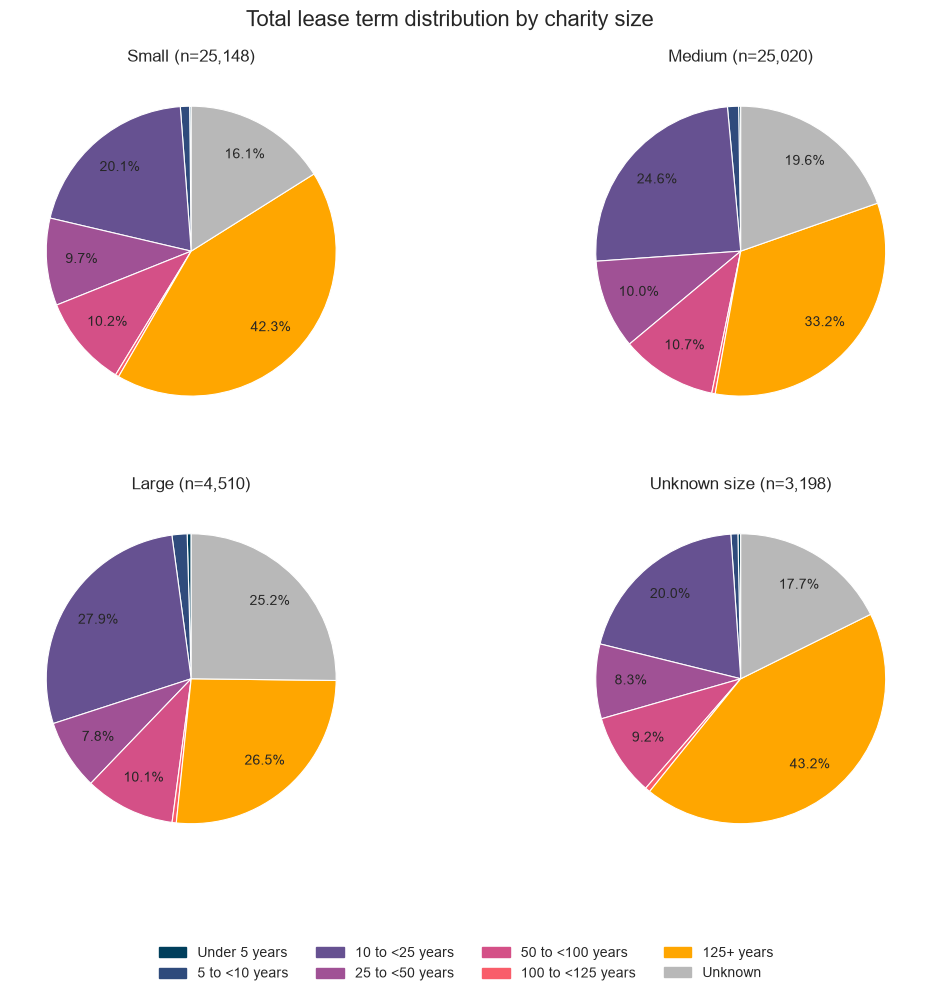

In [10]:
palette = ["#003f5c", "#2f4b7c", "#665191", "#a05195", "#d45087", "#f95d6a", "#ffa600", "#b8b8b8"]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, size in zip(axes.flat, lease_term_table.index):
    counts = lease_term_table.loc[size]
    shown = counts[counts > 0]
    shown_colors = [palette[term_order.index(label)] for label in shown.index]
    if shown.empty:
        ax.text(0.5, 0.5, "No matched charities", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
        continue
    ax.pie(
        shown, colors=shown_colors, startangle=90,
        autopct=lambda pct: f"{pct:.1f}%" if pct >= 3 else "",
        pctdistance=0.76, wedgeprops={"edgecolor": "white", "linewidth": 0.8},
    )
    ax.set_title(f"{size} (n={counts.sum():,})")
fig.legend(handles=[Patch(color=c, label=l) for l, c in zip(term_order, palette)], loc="lower center", ncol=4, frameon=False)
fig.suptitle("Total lease term distribution by charity size", fontsize=16, y=0.98)
fig.subplots_adjust(bottom=0.13, top=0.92, hspace=0.18)
plt.show()

### Lease term by charity size (reversed)

Same eligible Registered Leases cohort as above, but each pie is a **lease term band** and the slices show the **charity size** mix within that band. Percentages use charities in that term band as the denominator.

In [11]:
size_order = SIZE_ORDER
size_palette = ["#003f5c", "#665191", "#d45087", "#b8b8b8"]

term_size_table = lease_term_table.T.reindex(index=term_order, columns=size_order, fill_value=0)
term_size_percent = term_size_table.div(term_size_table.sum(axis=1).replace(0, np.nan), axis=0).mul(100)
term_size_percent.round(1)

charity_size,Small,Medium,Large,Unknown size
term_band,,,,
Under 5 years,32.80,44.30,15.30,7.60
5 to <10 years,38.70,46.20,11.40,3.70
10 to <25 years,38.60,47.00,9.60,4.90
25 to <50 years,44.00,44.90,6.30,4.80
50 to <100 years,42.80,44.70,7.60,4.90
100 to <125 years,41.80,41.40,9.10,7.80
125+ years,49.40,38.60,5.50,6.40
Unknown,37.90,46.10,10.70,5.30


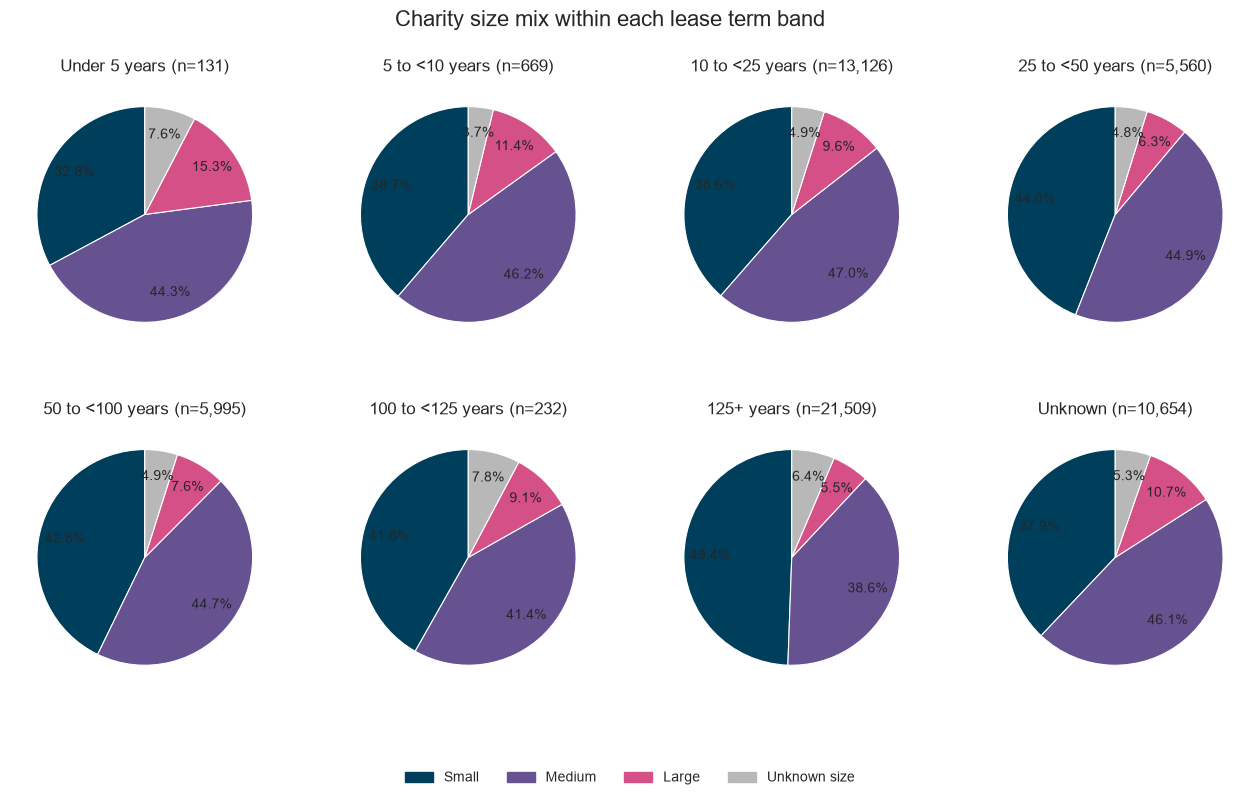

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, term in zip(axes.flat, term_order):
    counts = term_size_table.loc[term]
    shown = counts[counts > 0]
    shown_colors = [size_palette[size_order.index(label)] for label in shown.index]
    if shown.empty:
        ax.text(0.5, 0.5, "No matched charities", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
        continue
    ax.pie(
        shown,
        colors=shown_colors,
        startangle=90,
        autopct=lambda pct: f"{pct:.1f}%" if pct >= 3 else "",
        pctdistance=0.76,
        wedgeprops={"edgecolor": "white", "linewidth": 0.8},
    )
    ax.set_title(f"{term} (n={counts.sum():,})")
fig.legend(handles=[Patch(color=c, label=l) for l, c in zip(size_order, size_palette)], loc="lower center", ncol=4, frameon=False)
fig.suptitle("Charity size mix within each lease term band", fontsize=16, y=0.98)
fig.subplots_adjust(bottom=0.12, top=0.90, hspace=0.22)
plt.show()

## Estimated remaining lease years

The cohort excludes raw lease matches classified as freehold. These estimates use `lease_date_of_lease` plus the parsed year duration, evaluated
on the reference date printed above. They do not use the commencement date written
inside the lease term. Zero includes estimates at or before that reference date;
it does not establish that occupation ended. Unparsed estimates remain unknown.

In [13]:
lease_parse_summary = leases["lease_term_parse_status"].value_counts(dropna=False).rename_axis("parse_status").to_frame("lease_matches")
lease_parse_summary["share_of_lease_matches_pct"] = 100 * lease_parse_summary["lease_matches"] / len(leases) if len(leases) else np.nan
display(lease_parse_summary)
remaining_years = pd.to_numeric(leases["lease_years_remaining"], errors="coerce")
remaining_summary = pd.Series({
    "Eligible Registered Leases matches": len(leases),
    "Known remaining-year estimates": int(remaining_years.notna().sum()),
    "Unknown remaining-year estimates": int(remaining_years.isna().sum()),
    "Zero years remaining (floored)": int(remaining_years.eq(0).sum()),
    "Median known years remaining": remaining_years.median(),
    "Known estimates over 20 years": int(remaining_years.gt(20).sum()),
}).to_frame("value")
display(remaining_summary)
assert lease_term_table.to_numpy().sum() == len(leases)

,lease_matches,share_of_lease_matches_pct
parse_status,,
estimated_from_deed_date,47208,81.57
unparsed,10181,17.59
missing,487,0.84


,value
Eligible Registered Leases matches,"57,876.00"
Known remaining-year estimates,"47,208.00"
Unknown remaining-year estimates,"10,668.00"
Zero years remaining (floored),"5,150.00"
Median known years remaining,71.57
Known estimates over 20 years,"28,098.00"


## Geography: district codes, named upper-tier authorities, and country

Use the geography already present in the output: `local_authority_code` for
local-authority codes, and `UTLA` with `UTLA_name` for named upper-tier authorities.
These are different geographic levels and are summarised separately. Country is
derived from the leading letter of `local_authority_code`; missing codes remain
**Unknown**. This is register geography, not the location of every matched property.

Tables report raw lease-match counts, eligible leasehold-match counts, known total terms, median term, the share of known terms over
20 years, and the lease-match rate among charities explicitly reporting land/buildings.
Unknown land responses are excluded from that last denominator and shown separately.

In [14]:
print(f"Local authority code found for {(charities['local_authority'] != 'Unknown').sum():,} of {len(charities):,} charities")
print(f"Named upper-tier authority available for {charities['UTLA_name'].notna().sum():,} charities")


Local authority code found for 170,246 of 171,870 charities
Named upper-tier authority available for 169,979 charities


In [15]:
local_authority_summary = geographic_summary(charities, "local_authority")
upper_tier_summary = geographic_summary(charities, "upper_tier_authority")
country_summary = geographic_summary(charities, "country")

print("Local authority code summary")
display(local_authority_summary.head(20).style.format({
    "median_lease_term_years": "{:.1f}",
    "leases_over_20_years_pct": "{:.1f}%",
    "land_reporting_matched_to_leases_pct": "{:.1f}%",
}))
print("Top 20 named upper-tier authorities by lease matches")
display(upper_tier_summary.head(20).round(1))
print("Country summary")
display(country_summary.style.format({
    "median_lease_term_years": "{:.1f}",
    "leases_over_20_years_pct": "{:.1f}%",
    "land_reporting_matched_to_leases_pct": "{:.1f}%",
}))

Local authority code summary


,local_authority,charities,unknown_land_response,lease_matches,eligible_lease_matches,known_lease_terms,median_lease_term_years,leases_20_years_or_less,leases_over_20_years,leases_over_20_years_pct,land_reporting_charities,land_reporting_matched_to_leases_pct
0,E09000033,3160,110,1867,1846,1285,99.0,542,743,57.8%,581,55.9%
1,E09000001,1569,60,1207,1203,756,16.0,422,334,44.2%,278,73.0%
2,E09000007,2219,104,1170,1156,780,99.0,304,476,61.0%,476,52.5%
3,E08000025,2572,172,935,920,760,99.0,186,574,75.5%,827,38.6%
4,E06000023,1594,69,930,914,564,99.0,174,390,69.1%,423,53.7%
5,E09000012,1707,96,812,804,702,99.0,246,456,65.0%,411,47.4%
6,E08000003,1533,80,778,765,652,125.0,177,475,72.9%,405,48.6%
7,E06000065,2579,78,736,711,588,70.0,178,410,69.7%,1049,28.0%
8,E08000039,1233,50,711,705,619,200.0,75,544,87.9%,424,52.1%
9,E09000019,1596,77,699,687,495,99.0,199,296,59.8%,351,52.4%


Top 20 named upper-tier authorities by lease matches


,upper_tier_authority,charities,unknown_land_response,lease_matches,eligible_lease_matches,known_lease_terms,median_lease_term_years,leases_20_years_or_less,leases_over_20_years,leases_over_20_years_pct,land_reporting_charities,land_reporting_matched_to_leases_pct
0,Westminster (E09000033),3157,110,1867,1846,1285,99.00,542,743,57.80,581,55.90
1,Hampshire (E10000014),4212,128,1438,1402,1157,60.00,324,833,72.00,1326,38.90
2,Kent (E10000016),4650,192,1355,1314,1077,75.00,366,711,66.00,1597,30.90
3,Surrey (E10000030),4021,125,1330,1297,1081,99.00,332,749,69.30,1222,38.50
4,Devon (E10000008),3572,123,1212,1165,939,99.00,250,689,73.40,1431,34.90
5,City of London (E09000001),1571,60,1209,1205,757,16.00,422,335,44.30,278,73.00
6,Camden (E09000007),2219,104,1170,1156,780,99.00,304,476,61.00,476,52.50
7,Lancashire (E10000017),2793,122,1133,1112,999,999.00,177,822,82.30,1030,42.70
8,Essex (E10000012),3800,156,1094,1059,880,50.00,290,590,67.00,1289,32.30
9,Hertfordshire (E10000015),3620,131,1091,1060,862,99.00,226,636,73.80,1018,36.10


Country summary


,country,charities,unknown_land_response,lease_matches,eligible_lease_matches,known_lease_terms,median_lease_term_years,leases_20_years_or_less,leases_over_20_years,leases_over_20_years_pct,land_reporting_charities,land_reporting_matched_to_leases_pct
0,England,161751,7088,56931,55588,45281,99.0,12673,32608,72.0%,52750,36.3%
1,Wales,8212,450,2355,2284,1938,40.0,532,1406,72.5%,3197,31.7%
2,Unknown,1624,133,4,4,3,25.0,1,2,66.7%,504,0.4%
3,Channel Islands,9,0,0,0,0,nan,0,0,nan%,0,nan%
4,Isle of Man,6,0,0,0,0,nan,0,0,nan%,0,nan%
5,Northern Ireland,36,0,0,0,0,nan,0,0,nan%,4,0.0%
6,Scotland,232,2,0,0,0,nan,0,0,nan%,28,0.0%


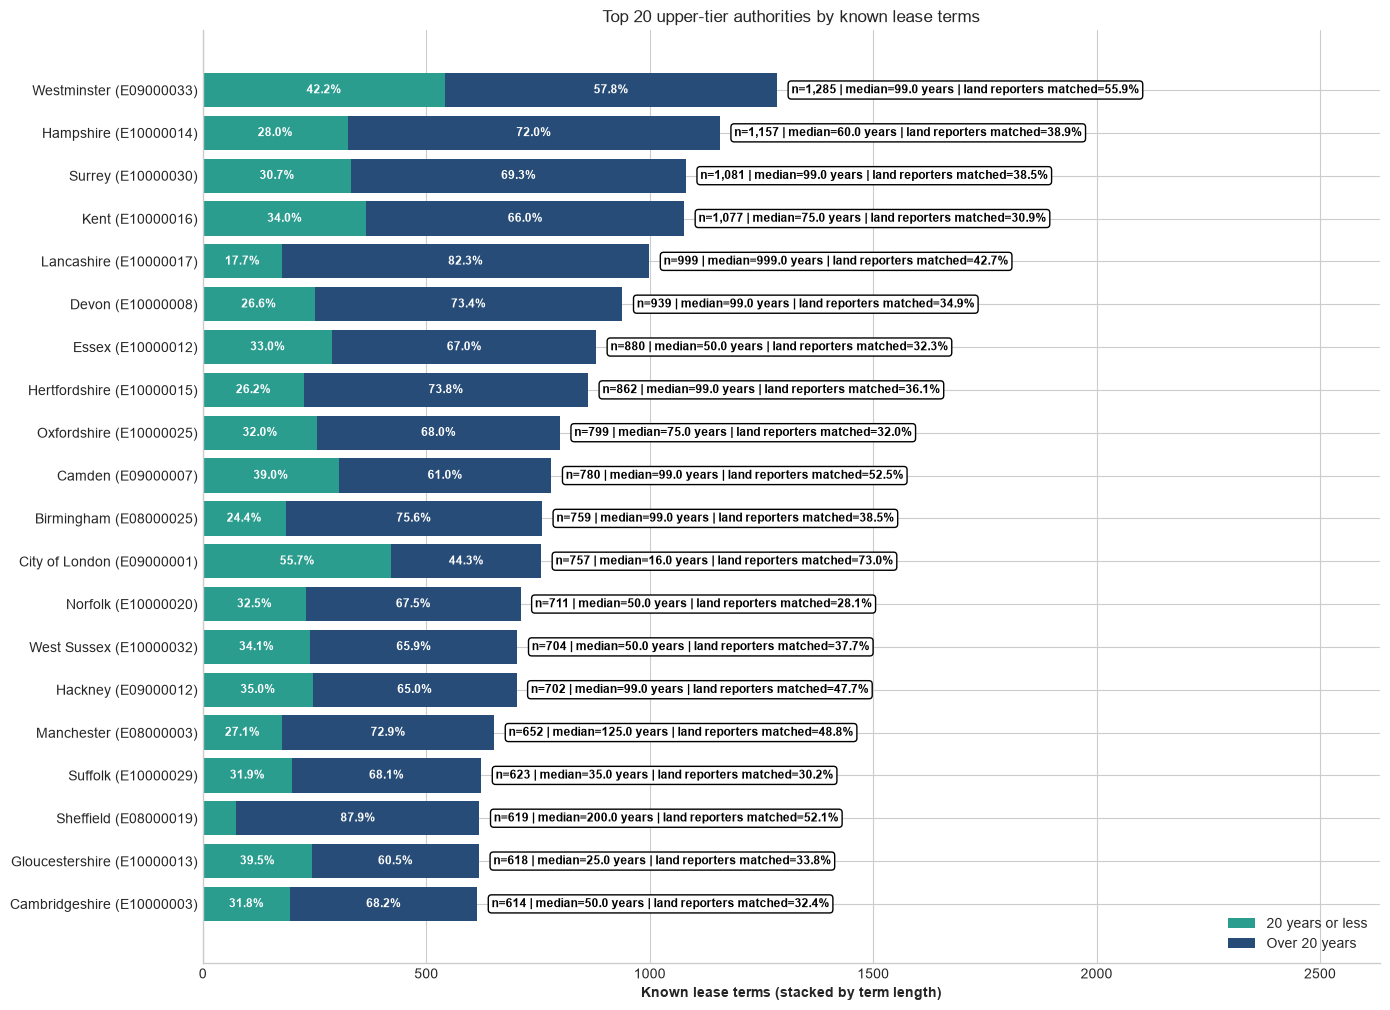

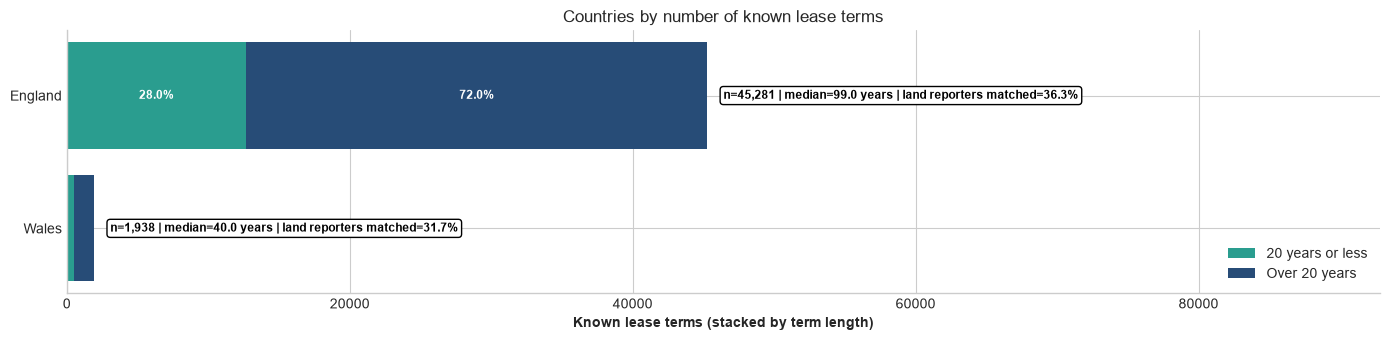

In [16]:
def plot_known_terms(summary, geography, title):
    top_20 = (
        summary.query(f"{geography} != 'Unknown' and known_lease_terms > 0")
        .nlargest(20, "known_lease_terms")
        .sort_values("known_lease_terms")
    )
    if top_20.empty:
        print(f"{title}: no known terms")
        return
    fig, ax = plt.subplots(figsize=(14, max(3.5, 0.42 * len(top_20) + 1.8)))
    short = top_20["leases_20_years_or_less"]
    long = top_20["leases_over_20_years"]
    ax.barh(top_20[geography], short, color="#2a9d8f", label="20 years or less")
    ax.barh(top_20[geography], long, left=short, color="#274c77", label="Over 20 years")

    for y, (_, row) in enumerate(top_20.iterrows()):
        total = row["known_lease_terms"]
        short_pct = 100 * row["leases_20_years_or_less"] / total
        long_pct = 100 * row["leases_over_20_years"] / total
        if row["leases_20_years_or_less"] >= top_20["known_lease_terms"].max() * 0.06:
            ax.text(row["leases_20_years_or_less"] / 2, y, f"{short_pct:.1f}%", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
        if row["leases_over_20_years"] >= top_20["known_lease_terms"].max() * 0.06:
            ax.text(row["leases_20_years_or_less"] + row["leases_over_20_years"] / 2, y, f"{long_pct:.1f}%", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
        median = row["median_lease_term_years"]
        land_match_pct = row["land_reporting_matched_to_leases_pct"]
        detail = (
            f"  n={int(total):,} | median={median:.1f} years | "
            f"land reporters matched={land_match_pct:.1f}%"
        )
        ax.text(
            total + top_20["known_lease_terms"].max() * 0.025, y, detail.strip(),
            ha="left", va="center", fontsize=8.5, fontweight="bold", color="black",
            bbox={"boxstyle": "round,pad=0.28", "facecolor": "#ffffff", "edgecolor": "black"},
        )

    ax.set_title(title)
    ax.set_xlabel("Known lease terms (stacked by term length)", fontweight="bold")
    ax.legend(loc="lower right", frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(0, top_20["known_lease_terms"].max() * 2.05)
    plt.tight_layout()
    plt.show()

plot_known_terms(
    upper_tier_summary, "upper_tier_authority",
    "Top 20 upper-tier authorities by known lease terms",
)
plot_known_terms(
    country_summary, "country",
    "Countries by number of known lease terms",
)

## Interpretation notes

- The population contains active charities only, with one row per registered charity number.
- Match flags describe selected address matches, not verified tenure or all properties held.
- Both source flags and raw evidence remain available. Charity freeholders take tenure precedence; other registered-lease matches select leasehold.
- Review flags mark uncertainty. The review table reports both flagged and unflagged matches; unflagged does not mean independently verified.
- The source-status message reports whether the lease CSV was incomplete. Unmatched charities may occur in the omitted records.
- Unknown land responses, size, geography and total terms remain visible rather than being counted as negative responses.
- Lease-duration and remaining-year cohorts exclude raw lease matches classified as freehold; raw coverage counts retain them.
- Lease expiry and remaining years are estimates from the deed date plus the parsed duration, with remaining years floored at zero. The written commencement date in the term is not used by this output.
- Geography comes from the input register. Upper-tier names and district codes refer to different levels and may use different lookup vintages.

## Findings for the selected completed run

This narrative uses the same validated data as the tables and figures above.
Source coverage includes raw matches; duration statistics use the shared eligible
leasehold cohort. These are descriptive address-linkage findings, not verified
property holdings or population-level ownership estimates.


In [17]:
eligible = charities.loc[charities["eligible_registered_leases"]]
known_total = eligible["lease_term_years_num"].dropna()
known_remaining = pd.to_numeric(eligible["lease_years_remaining"], errors="coerce").dropna()
raw_lease_count = int(charities["matched_registered_leases"].sum())
suppressed = raw_lease_count - len(eligible)
land_reporters = charities.loc[charities["reports_land"]]
land_rate = 100 * land_reporters["matched_registered_leases"].mean() if len(land_reporters) else np.nan
coverage = charities["land_registry_match"].value_counts().reindex(MATCH_ORDER, fill_value=0)
incomplete = bool(charities["lease_source_incomplete"].any())
reference = ", ".join(map(str, pd.to_datetime(charities["lease_term_as_of_date"]).dt.date.unique()))
report = f"""
### Run and population

Run `{DATA_PATH.parent.name}` contains **{len(charities):,} charities**. Lease
estimates use reference date **{reference}**. The recorded incomplete-source
indicator is **{incomplete}**; this is a syntactic truncation check rather than
independent confirmation of exhaustive source coverage.

### Address-linkage coverage

**{int(charities['any_land_registry_match'].sum()):,} charities
({100 * charities['any_land_registry_match'].mean():.2f}%)** have at least one
selected source match. The population separates into **{int(coverage['Both sources']):,}
both-source matches**, **{int(coverage['Registered Leases only']):,} lease-only
matches**, **{int(coverage['CCOD only']):,} CCOD-only matches**, and
**{int(coverage['No Land Registry match']):,} unmatched charities**.
Adding raw source totals without subtracting their intersection double-counts
charities. Unmatched addresses do not establish absence of property or a lease.

### Selected tenure and eligible leases

There are **{int((charities['registry_tenure'] == 'Freehold').sum()):,} freehold**,
**{int((charities['registry_tenure'] == 'Lease').sum()):,} leasehold**, and
**{int((charities['registry_tenure'] == 'No data').sum()):,} No data** rows.
Of **{raw_lease_count:,} raw registered-lease matches**, **{suppressed:,}** have
selected freehold status and deliberately suppressed estimates, leaving
**{len(eligible):,} eligible leasehold matches**. CCOD-only freehold tenure does
not itself identify the charity as proprietor.

### Duration, missingness and review

Within the eligible cohort, **{len(known_total):,}** have a known positive total
term and **{len(eligible) - len(known_total):,}** have an unknown total term.
The median known total term is **{known_total.median():.1f} years**;
**{100 * known_total.gt(20).mean():.1f}%** of known terms exceed 20 years.
There are **{len(known_remaining):,}** known remaining-year estimates, with a
median of **{known_remaining.median():.1f} years** and
**{int(known_remaining.eq(0).sum()):,}** estimates floored at zero.
Deed-date estimation can differ from legal commencement and does not establish
whether a lease remains effective.

**{int(charities['review'].sum()):,} rows** trigger at least one review rule.
**{int(charities['charity_has_land'].isna().sum()):,}** land/buildings responses
are unknown. Among **{len(land_reporters):,}** explicit land/buildings reporters,
**{land_rate:.2f}%** have a raw lease match. These rates describe linkage
coverage. Source quality, shared addresses and parse success can affect
comparisons between charity groups and geographies.
"""
display(Markdown(report))



### Run and population

Run `20260929_210521_052655Z` contains **171,870 charities**. Lease
estimates use reference date **2026-09-29**. The recorded incomplete-source
indicator is **False**; this is a syntactic truncation check rather than
independent confirmation of exhaustive source coverage.

### Address-linkage coverage

**90,875 charities
(52.87%)** have at least one
selected source match. The population separates into **47,118
both-source matches**, **12,172 lease-only
matches**, **31,585 CCOD-only matches**, and
**80,995 unmatched charities**.
Adding raw source totals without subtracting their intersection double-counts
charities. Unmatched addresses do not establish absence of property or a lease.

### Selected tenure and eligible leases

There are **32,264 freehold**,
**58,611 leasehold**, and
**80,995 No data** rows.
Of **59,290 raw registered-lease matches**, **1,414** have
selected freehold status and deliberately suppressed estimates, leaving
**57,876 eligible leasehold matches**. CCOD-only freehold tenure does
not itself identify the charity as proprietor.

### Duration, missingness and review

Within the eligible cohort, **47,222** have a known positive total
term and **10,654** have an unknown total term.
The median known total term is **99.0 years**;
**72.0%** of known terms exceed 20 years.
There are **47,208** known remaining-year estimates, with a
median of **71.6 years** and
**5,150** estimates floored at zero.
Deed-date estimation can differ from legal commencement and does not establish
whether a lease remains effective.

**70,581 rows** trigger at least one review rule.
**7,673** land/buildings responses
are unknown. Among **56,483** explicit land/buildings reporters,
**35.72%** have a raw lease match. These rates describe linkage
coverage. Source quality, shared addresses and parse success can affect
comparisons between charity groups and geographies.
